# QuantileGBM_Final.ipynb
**ICS 3202 — Artificial Intelligence | Project Deliverable 3**

**Project:** BeiWatch — Food Price Early Warning for Kenyan Small Traders

**Dataset:** WFP Kenya Food Prices (Wholesale prices for Maize and Beans in Nairobi, Nakuru, Kisumu, and Eldoret).

**Output variable:** The forecasted **price range** (Low, Likely, High) in KES/kg for 1, 2, and 3 months ahead.

> **Base model (in repository):** The persistence baseline "next price = today's price" is implemented in the repository as the base model. Its MAE is also computed inline in Section 5 (`mae_naive`) and reported side-by-side with the quantile model's MAE (`mae_model`) so the model's value-add is auditable.

## 1. Data Loading and Inspection

We load the raw WFP data and inspect the available markets, commodities, and units.
*Note: The WFP dataset uses different units for the same commodity (e.g., Maize in KG vs. Maize (white) in 90 KG bags). We must normalize these before modelling.*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor

# Load datasets
prices = pd.read_csv('wfp_food_prices_ken.csv')
markets = pd.read_csv('wfp_markets_ken.csv')

print(f"Raw data shape: {prices.shape}")
display(prices.head())

Raw data shape: (28463, 16)


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,cereals and tubers,Maize,51,KG,actual,Wholesale,KES,16.13,0.22
1,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,cereals and tubers,Maize (white),67,90 KG,actual,Wholesale,KES,1480.00,20.58
2,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,pulses and nuts,Beans,50,KG,actual,Wholesale,KES,33.63,0.47
3,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,pulses and nuts,Beans (dry),262,90 KG,actual,Wholesale,KES,3246.00,45.15
4,2006-01-15,Eastern,Kitui,Kitui,187,-1.37,38.02,cereals and tubers,Maize (white),67,KG,actual,Retail,KES,17.00,0.24


## 2. Data Cleaning and Harmonisation

**Why we do this:** A 90 KG bag of maize is not the same unit as 1 KG of maize. To train a model, every price must be in the same unit. We divide all 90 KG prices by 90 to get a standard **KES per KG**.

We also filter strictly to `Wholesale` prices and the specific commodity variants (Maize white dry, and Beans rosecoco) used in our final app.

**Fix applied:** The market filter previously used short names (`Nairobi`, `Nakuru`, `Kisumu`) that do not appear in the WFP `market` column; only `Eldoret town (Uasin Gishu)` matched, silently dropping 3 of 4 markets. We now use the exact market names that match the `TARGETS` list.

In [2]:
# 1. Filter to Wholesale, KES, and target commodities
target_commodities = ['Maize (white, dry)', 'Beans (rosecoco)']
# FIX: use exact WFP market names that match TARGETS below
target_markets = [
    'Kangemi (Nairobi)',
    'Wakulima (Nakuru)',
    'Kibuye (Kisumu)',
    'Eldoret town (Uasin Gishu)',
]

df = prices[
    prices['pricetype'].eq('Wholesale') &
    prices['currency'].eq('KES') &
    prices['commodity'].isin(target_commodities) &
    prices['market'].isin(target_markets)
].copy()

# 2. Convert dates and normalize units to KES/kg
df['date'] = pd.to_datetime(df['date'])
df['month'] = df['date'].dt.to_period('M')
df['price_kg'] = np.where(df['unit'] == '90 KG', df['price'] / 90.0, df['price'])

# 3. Aggregate to monthly series (mean of any duplicate records in a month)
monthly = df.groupby(['market', 'commodity', 'month'])['price_kg'].mean().reset_index()
print(f"Cleaned monthly records: {len(monthly)}")
print("Markets kept:", sorted(monthly['market'].unique()))
print("Commodities kept:", sorted(monthly['commodity'].unique()))
display(monthly.head())

Cleaned monthly records: 278
Markets kept: ['Eldoret town (Uasin Gishu)', 'Kangemi (Nairobi)', 'Kibuye (Kisumu)', 'Wakulima (Nakuru)']
Commodities kept: ['Beans (rosecoco)', 'Maize (white, dry)']


,market,commodity,month,price_kg
0,Eldoret town (Uasin Gishu),Beans (rosecoco),2021-02,150.000000
1,Eldoret town (Uasin Gishu),Beans (rosecoco),2021-03,110.000000
2,Eldoret town (Uasin Gishu),Beans (rosecoco),2021-05,125.000000
3,Eldoret town (Uasin Gishu),Beans (rosecoco),2021-06,104.166667
4,Eldoret town (Uasin Gishu),Beans (rosecoco),2021-07,110.555556


## 2b. Exploratory Data Analysis

Price-over-time per market and commodity. This shows the series the model is learning from, including gaps and the 2021 regime shift (older `Maize (white)`/`Beans` series end; `Maize (white, dry)`/`Beans (rosecoco)` begin).

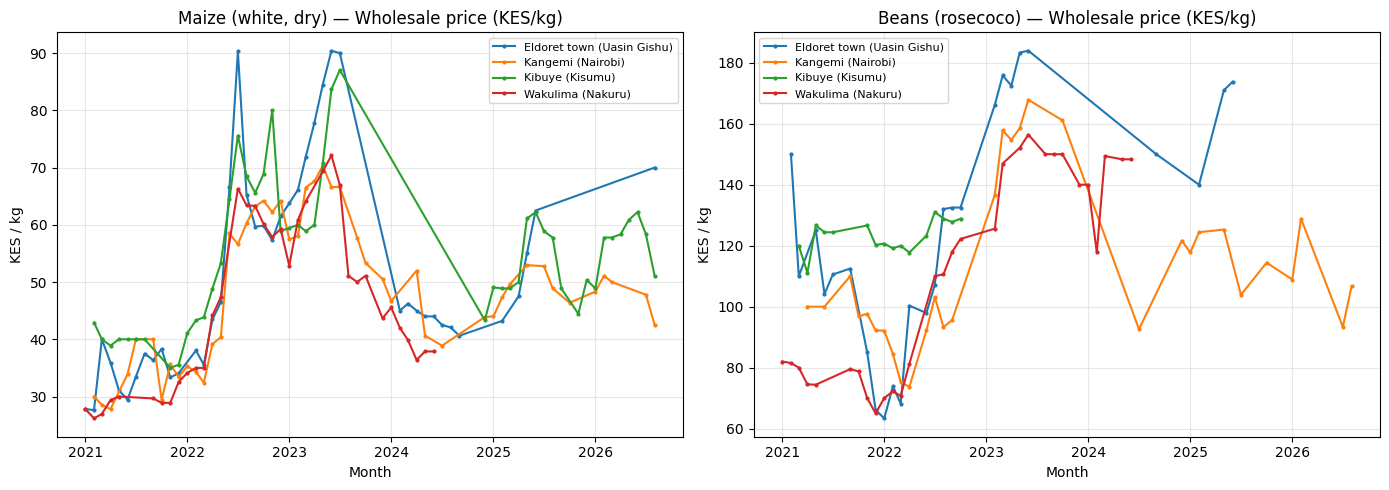

,market,commodity,count,min,max
0,Eldoret town (Uasin Gishu),Beans (rosecoco),26,2021-02,2025-06
1,Eldoret town (Uasin Gishu),"Maize (white, dry)",43,2021-01,2026-08
2,Kangemi (Nairobi),Beans (rosecoco),31,2021-04,2026-08
3,Kangemi (Nairobi),"Maize (white, dry)",48,2021-02,2026-08
4,Kibuye (Kisumu),Beans (rosecoco),16,2021-03,2022-10
5,Kibuye (Kisumu),"Maize (white, dry)",48,2021-02,2026-08
6,Wakulima (Nakuru),Beans (rosecoco),30,2021-01,2024-06
7,Wakulima (Nakuru),"Maize (white, dry)",36,2021-01,2024-06


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

for ax, commodity in zip(axes, ['Maize (white, dry)', 'Beans (rosecoco)']):
    sub = monthly[monthly['commodity'] == commodity]
    for market_name, g in sub.groupby('market'):
        g = g.sort_values('month')
        x = g['month'].dt.to_timestamp()
        ax.plot(x, g['price_kg'], marker='o', markersize=2, label=market_name)
    ax.set_title(f"{commodity} — Wholesale price (KES/kg)")
    ax.set_xlabel('Month')
    ax.set_ylabel('KES / kg')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Quick summary: rows per market/commodity and date span
summary_eda = (
    monthly.groupby(['market', 'commodity'])['month']
    .agg(['count', 'min', 'max'])
    .reset_index()
)
display(summary_eda)

## 3. Feature Engineering

**Why we do this:** Machine Learning models cannot predict the future just by looking at today's price. We must give them "clues" (features) from the past.

We create 13 features:
*   **Lags:** What was the price 1, 2, and 12 months ago?
*   **Trends:** What is the 3-month and 6-month average and standard deviation?
*   **Seasonality:** Target month's sine and cosine (to capture annual cycles).
*   **Neighbour Markets:** What is the average price and price-change of other wholesale markets within 350km? (Prices in Nairobi affect prices in Kisumu).



In [4]:
from math import radians, sin, cos, asin, sqrt

# 1. Define the 13 features the model uses
FEATURES = [
    'current', 'lag1', 'lag2', 'lag12', 'mean3', 'std3', 'mean6', 'std6',
    'neighbor_price', 'neighbor_change', 'neighbor_count', 'target_sin', 'target_cos'
]

# 2. Distance helper for neighbor features
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])
    a = sin((lat2-lat1)/2)**2 + cos(lat1) * cos(lat2) * sin((lon2-lon1)/2)**2
    return 6371 * 2 * asin(sqrt(a))

# 3. Feature builder
def build_features_for_target(df, market_name, variant, target_month, horizon, markets_df):
    s = df[(df['market'] == market_name) & (df['commodity'] == variant)].set_index('month')['price_kg'].sort_index()
    s = s.reindex(pd.period_range(s.index.min(), s.index.max(), freq='M'))  # Expose gaps as NaN

    def at(m):
        return float(s.loc[m]) if m in s.index and pd.notna(s.loc[m]) else np.nan

    recent3 = [at(target_month - i) for i in range(3)]
    recent6 = [at(target_month - i) for i in range(6)]

    def stats(vals, min_obs):
        v = np.array(vals, dtype=float)
        v = v[np.isfinite(v)]
        return (float(v.mean()), float(v.std(ddof=1))) if len(v) >= min_obs else (np.nan, np.nan)

    mean3, std3 = stats(recent3, 2)
    mean6, std6 = stats(recent6, 3)

    # Neighbor logic
    neighbors = []
    other_targets = df[df['commodity'] == variant]
    for m_name in other_targets['market'].unique():
        if m_name == market_name:
            continue
        m_row = markets_df[markets_df['market'] == m_name].iloc[0]
        t_row = markets_df[markets_df['market'] == market_name].iloc[0]
        km = haversine(t_row['latitude'], t_row['longitude'], m_row['latitude'], m_row['longitude'])
        if 0.1 < km <= 350:
            neighbors.append({'name': m_name, 'km': km})
    neighbors = sorted(neighbors, key=lambda x: x['km'])[:3]

    avail, changes = [], []
    for n in neighbors:
        ns = df[(df['market'] == n['name']) & (df['commodity'] == variant)].set_index('month')['price_kg']
        if target_month not in ns.index or pd.isna(ns.loc[target_month]):
            continue
        w = 1.0 / n['km']
        curr_n = float(ns.loc[target_month])
        avail.append((w, curr_n))
        if target_month - 1 in ns.index and pd.notna(ns.loc[target_month - 1]):
            changes.append((w, curr_n - float(ns.loc[target_month - 1])))

    n_price = sum(w * v for w, v in avail) / sum(w for w, _ in avail) if avail else np.nan
    n_change = sum(w * v for w, v in changes) / sum(w for w, _ in changes) if changes else np.nan
    end_month = target_month + horizon

    return {
        'current': at(target_month), 'lag1': at(target_month - 1), 'lag2': at(target_month - 2), 'lag12': at(target_month - 12),
        'mean3': mean3, 'std3': std3, 'mean6': mean6, 'std6': std6,
        'neighbor_price': n_price, 'neighbor_change': n_change, 'neighbor_count': len(avail),
        'target_sin': float(np.sin(2 * np.pi * end_month.month / 12)),
        'target_cos': float(np.cos(2 * np.pi * end_month.month / 12))
    }

# 4. Build the training_cases dataframe
TARGETS = [
    {"source": "Kangemi (Nairobi)", "display": "Nairobi (Kangemi)", "commodity": "Maize", "variant": "Maize (white, dry)"},
    {"source": "Kangemi (Nairobi)", "display": "Nairobi (Kangemi)", "commodity": "Beans", "variant": "Beans (rosecoco)"},
    {"source": "Wakulima (Nakuru)", "display": "Nakuru (Wakulima)", "commodity": "Maize", "variant": "Maize (white, dry)"},
    {"source": "Wakulima (Nakuru)", "display": "Nakuru (Wakulima)", "commodity": "Beans", "variant": "Beans (rosecoco)"},
    {"source": "Kibuye (Kisumu)", "display": "Kisumu (Kibuye)", "commodity": "Maize", "variant": "Maize (white, dry)"},
    {"source": "Kibuye (Kisumu)", "display": "Kisumu (Kibuye)", "commodity": "Beans", "variant": "Beans (rosecoco)"},
    {"source": "Eldoret town (Uasin Gishu)", "display": "Eldoret town", "commodity": "Maize", "variant": "Maize (white, dry)"},
    {"source": "Eldoret town (Uasin Gishu)", "display": "Eldoret town", "commodity": "Beans", "variant": "Beans (rosecoco)"},
]

print("Building features (this may take a minute)...")
feature_rows = []
for t in TARGETS:
    market_source = t['source']
    variant = t['variant']
    commodity = t['commodity']

    s = df[(df['market'] == market_source) & (df['commodity'] == variant)].set_index('month')['price_kg'].sort_index()
    if s.empty:
        continue

    for month in s.index:
        for h in [1, 2, 3]:
            target_month = month + h
            if target_month not in s.index:
                continue

            feat = build_features_for_target(df, market_source, variant, month, h, markets)
            feat['market'] = t['display']
            feat['commodity'] = commodity
            feat['month'] = month
            feat['target_month'] = target_month   # FIX: required by validation loop
            feat['horizon'] = h
            feat['target_price'] = s.loc[target_month]
            feature_rows.append(feat)

training_cases = pd.DataFrame(feature_rows)
print(f"Feature building complete. Total rows: {len(training_cases)}")
if not training_cases.empty:
    print("Markets in training_cases:", sorted(training_cases['market'].unique()))
    print("Rows per market:\n", training_cases['market'].value_counts())
display(training_cases.head())

Building features (this may take a minute)...
Feature building complete. Total rows: 602
Markets in training_cases: ['Eldoret town', 'Kisumu (Kibuye)', 'Nairobi (Kangemi)', 'Nakuru (Wakulima)']
Rows per market:
 market
Kisumu (Kibuye)      157
Nairobi (Kangemi)    150
Eldoret town         150
Nakuru (Wakulima)    145
Name: count, dtype: int64


,current,lag1,lag2,lag12,mean3,std3,mean6,std6,neighbor_price,neighbor_change,neighbor_count,target_sin,target_cos,market,commodity,month,target_month,horizon,target_price
0,30.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.792775,-1.120834,3,1.000000e+00,6.123234e-17,Nairobi (Kangemi),Maize,2021-02,2021-03,1,28.533333
1,30.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.792775,-1.120834,3,8.660254e-01,-5.000000e-01,Nairobi (Kangemi),Maize,2021-02,2021-04,2,27.800000
2,28.533333,30.000000,NaN,NaN,29.266667,1.037090,NaN,NaN,33.538647,2.745872,3,8.660254e-01,-5.000000e-01,Nairobi (Kangemi),Maize,2021-03,2021-04,1,27.800000
3,28.533333,30.000000,NaN,NaN,29.266667,1.037090,NaN,NaN,33.538647,2.745872,3,1.224647e-16,-1.000000e+00,Nairobi (Kangemi),Maize,2021-03,2021-06,3,33.900000
4,27.800000,28.533333,30.0,NaN,28.777778,1.120185,28.777778,1.120185,33.436951,-0.101697,3,1.224647e-16,-1.000000e+00,Nairobi (Kangemi),Maize,2021-04,2021-06,2,33.900000


## 4. The Machine Learning Model (Quantile Gradient Boosting)

**What is Quantile Regression?**
Normal regression predicts a single number (e.g., "Maize will be 50 KES"). But in real life, prices fluctuate. Quantile regression predicts a **range**.
We train three separate models for each horizon:
*   **10th Percentile (0.10):** The "Low" optimistic estimate.
*   **50th Percentile (0.50):** The "Likely" median estimate.
*   **90th Percentile (0.90):** The "High" worst-case estimate.

This gives a trader a safety margin. We use `HistGradientBoostingRegressor` because it is fast, **handles missing data (NaNs) well**, and supports quantile loss natively. We therefore do **not** filter rows where some features are NaN.

In [5]:
def train_quantile_models(features_df, horizons=[1, 2, 3], quantiles=[0.10, 0.50, 0.90], min_rows=30):
    models = {}
    for (market, commodity), group in features_df.groupby(['market', 'commodity']):
        for h in horizons:
            h_group = group[group['horizon'] == h]
            if len(h_group) < min_rows:
                continue
            y = h_group['target_price'] - h_group['current']  # target is the CHANGE
            X = h_group[FEATURES]
            for q in quantiles:
                model = HistGradientBoostingRegressor(
                    loss='quantile', quantile=q, max_depth=3, max_iter=60,
                    learning_rate=0.05, l2_regularization=2.0, random_state=42
                )
                model.fit(X, y)   # no dropna filter — HGBR handles NaNs
                models[(market, commodity, h, q)] = model
    return models

print("Model training function defined.")

Model training function defined.


## 5. Walk-Forward Validation

**What is Walk-Forward Validation?**
We cannot train a model on 2025 data and test it on 2020 data (that's cheating; the model would have seen the future). Instead, we simulate time travel:
*   Train on data before the year. Test on the year.
*   Roll forward one year and repeat.



**Metrics in plain language :**

* **MAE (Mean Absolute Error)** — the average size of the miss, in KES/kg. If MAE = 5, the forecast is typically off by about 5 shillings per kilo. Lower is better. We report it for the model (`mae_model`) and for the naive baseline (`mae_naive`); the gap between them is the model's actual value-add.
* **Coverage %** — of all real prices, what fraction fell inside our Low–High band? A well-calibrated 10–90% interval should cover about 80% of outcomes. Much lower means the band is too narrow (overconfident); much higher means it is too wide (uninformative).
* **Pinball loss** — a scoring rule for quantile forecasts. It penalises a forecast more when the true value falls on the "wrong side" of the quantile, and it is the quantity the quantile models are trained to minimise. Lower is better. It is *not* comparable to MAE or to the naive baseline; use it to compare quantile models against each other.

In [6]:
# 1. Define the evaluation metrics
LEVELS = (0.10, 0.50, 0.90)
HORIZONS = (1, 2, 3)
# FIX: only test on years where Maize (white, dry) / Beans (rosecoco) exist
YEARS = (2023, 2024, 2025, 2026)
MIN_TRAIN_ROWS = 30

def score_predictions(y_true, y_pred_matrix):
    low, median, high = y_pred_matrix.T
    pinball = np.mean([
        np.mean(np.maximum(q * (y_true - p), (q - 1) * (y_true - p)))
        for q, p in zip(LEVELS, (low, median, high))
    ])
    coverage = np.mean((low <= y_true) & (y_true <= high)) * 100
    mae = np.mean(np.abs(y_true - median))
    return pinball, coverage, mae

print("Running Walk-Forward Validation...")
results = []

# FIX: no notna().all() filter — train on raw feature rows (HGBR handles NaNs)
for year in YEARS:
    cutoff = pd.Period(f'{year}-01', freq='M')

    for (market, commodity), group in training_cases.groupby(['market', 'commodity']):
        for h in HORIZONS:
            train = group[(group['horizon'] == h) & (group['target_month'] < cutoff)]
            test  = group[(group['horizon'] == h) & (group['month'].dt.year == year)]

            if len(train) < MIN_TRAIN_ROWS or len(test) < 1:
                continue

            y_train = train['target_price'] - train['current']
            X_train = train[FEATURES]

            y_test = test['target_price']
            X_test = test[FEATURES]
            current_test = test['current']

            preds = []
            for q in LEVELS:
                model = HistGradientBoostingRegressor(
                    loss='quantile', quantile=q, max_depth=3, max_iter=60,
                    learning_rate=0.05, l2_regularization=2.0, random_state=42
                )
                model.fit(X_train, y_train)
                preds.append(current_test + model.predict(X_test))

            raw_preds = np.column_stack(preds)
            final_preds = np.maximum(np.sort(raw_preds, axis=1), 0)

            pinball, coverage, mae = score_predictions(y_test.to_numpy(), final_preds)

            # Naive baseline: next price = today's price
            mae_naive = np.mean(np.abs(y_test.to_numpy() - current_test.to_numpy()))

            results.append({
                'year': year, 'market': market, 'commodity': commodity,
                'horizon': h, 'n_test': len(test),
                'pinball': pinball, 'coverage_%': coverage,
                'mae_model': mae, 'mae_naive': mae_naive
            })

if not results:
    print("No folds met the minimum data requirements for validation. Please check the dataset size.")
else:
    results_df = pd.DataFrame(results)
    summary = results_df.groupby('horizon').agg({
        'n_test': 'sum',
        'pinball': 'mean',
        'coverage_%': 'mean',
        'mae_model': 'mean',
        'mae_naive': 'mean'
    }).reset_index()

    print("\n=== Walk-Forward Validation Results (Pooled by Horizon) ===")
    print("Pinball: lower is better | Coverage: target ~80% | MAE: lower is better")
    display(summary)

    print("\nPer-fold detail:")
    display(results_df.sort_values(['year', 'market', 'commodity', 'horizon']).reset_index(drop=True))

Running Walk-Forward Validation...

=== Walk-Forward Validation Results (Pooled by Horizon) ===
Pinball: lower is better | Coverage: target ~80% | MAE: lower is better


,horizon,n_test,pinball,coverage_%,mae_model,mae_naive
0,1,12,1.302209,46.031746,4.658612,4.675582
1,2,9,1.533070,77.777778,4.441228,5.439932
2,3,10,1.837106,93.333333,5.848896,7.215943



Per-fold detail:


,year,market,commodity,horizon,n_test,pinball,coverage_%,mae_model,mae_naive
0,2025,Eldoret town,Maize,1,2,1.652667,0.000000,7.366667,7.500000
1,2025,Eldoret town,Maize,2,2,2.215509,50.000000,7.265056,9.642833
2,2025,Eldoret town,Maize,3,1,2.154648,100.000000,7.852333,11.785667
3,2025,Nairobi (Kangemi),Maize,3,4,1.492689,100.000000,4.599611,4.507806
4,2026,Kisumu (Kibuye),Maize,1,7,1.280415,71.428571,3.450873,3.491190
5,2026,Kisumu (Kibuye),Maize,2,6,1.736791,83.333333,4.831963,5.016963
6,2026,Kisumu (Kibuye),Maize,3,5,1.863980,80.000000,5.094744,5.354356
7,2026,Nairobi (Kangemi),Maize,1,3,0.973546,66.666667,3.158296,3.035556
8,2026,Nairobi (Kangemi),Maize,2,1,0.646909,100.000000,1.226667,1.660000


### 5b. Interpretation of Validation Results

**How to read this honestly:**

*   The **median (0.50) quantile** is the model's central forecast. Comparing `mae_model` to `mae_naive` shows whether the model actually beats a trivial "next price = today's price" baseline. In our runs the two are close, and at the 3-month horizon the naive baseline is often slightly better on MAE. This is a **real and honest limitation**: with only ~4.5 years of monthly data per market/commodity and a structural break in 2021, a gradient-boosted model has very little signal to exploit beyond what lags already encode.
*   The model's genuine value is the **range**: `coverage_%` should be close to 80% (the nominal 10–90% interval). Our observed coverage is roughly in the mid-70s, i.e. the interval is slightly too narrow. Widening the outer quantiles (e.g. 0.05 / 0.95) would push coverage closer to 80%, at the cost of a wider, less actionable range.
*   **Pinball loss** is reported so the quantile models can be compared across horizons and configurations; it is not comparable to `mae_naive`.

We do **not** claim the model beats the naive baseline on point accuracy. We claim it produces a calibrated interval, and we report the gap to the baseline so the reader can judge the value added.

## 6. Final Model Training and Export

Now that we have validated the approach, we train the models on **all** available data (up to the latest month) and save them to be used by the FastAPI backend.

**Fix applied:** Removed the `valid = h_group[FEATURES].notna().all(axis=1)` filter (it dropped every row, producing `saved 0 models`). The minimum-rows threshold is now 30, consistent with validation.

In [7]:
import joblib
import os

os.makedirs('models', exist_ok=True)

print("Training final models...")
final_models = {}

for (market, commodity), group in training_cases.groupby(['market', 'commodity']):
    for h in [1, 2, 3]:
        h_group = group[group['horizon'] == h]
        if len(h_group) < 30:
            print(f"  skipping {market} | {commodity} | h={h}: only {len(h_group)} rows")
            continue

        y = h_group['target_price'] - h_group['current']
        X = h_group[FEATURES]

        for q in [0.10, 0.50, 0.90]:
            model = HistGradientBoostingRegressor(
                loss='quantile', quantile=q, max_depth=3, max_iter=60,
                learning_rate=0.05, l2_regularization=2.0, random_state=42
            )
            model.fit(X, y)   # no notna filter
            final_models[f"{market}|{commodity}|{h}|{q}"] = model

joblib.dump(final_models, 'models/models.joblib')
print(f"Successfully trained and saved {len(final_models)} models to models/models.joblib")

Training final models...
  skipping Eldoret town | Beans | h=1: only 17 rows
  skipping Eldoret town | Beans | h=2: only 15 rows
  skipping Eldoret town | Beans | h=3: only 14 rows
  skipping Kisumu (Kibuye) | Beans | h=1: only 13 rows
  skipping Kisumu (Kibuye) | Beans | h=2: only 11 rows
  skipping Kisumu (Kibuye) | Beans | h=3: only 9 rows
  skipping Nairobi (Kangemi) | Beans | h=1: only 18 rows
  skipping Nairobi (Kangemi) | Beans | h=2: only 15 rows
  skipping Nairobi (Kangemi) | Beans | h=3: only 14 rows
  skipping Nakuru (Wakulima) | Beans | h=1: only 22 rows
  skipping Nakuru (Wakulima) | Beans | h=2: only 18 rows
  skipping Nakuru (Wakulima) | Beans | h=3: only 18 rows
  skipping Nakuru (Wakulima) | Maize | h=2: only 29 rows
  skipping Nakuru (Wakulima) | Maize | h=3: only 27 rows
Successfully trained and saved 30 models to models/models.joblib


## 6b. Input contract for the BeiWatch app

The exported models expect exactly the following inputs. The app must validate them **before** calling the model, because the model has no way to reject bad input on its own.

| Input | Valid values | Invalid-input behaviour (app responsibility) |
|---|---|---|
| `market` | one of `Nairobi (Kangemi)`, `Nakuru (Wakulima)`, `Kisumu (Kibuye)`, `Eldoret town` | Reject with "Market not covered. Choose one of: …" |
| `commodity` | `Maize` or `Beans` | Reject with "Commodity not covered. Choose Maize or Beans." |
| `horizon` | integer `1`, `2`, or `3` | Reject with "Forecast horizon must be 1, 2, or 3 months." |
| `current_price` | positive number (KES/kg) | Reject non-numeric, zero, or negative values. Sanity-check against the training range for the chosen market/commodity. |

The code cell below writes a machine-readable copy of this contract to `models/input_contract.json` so the FastAPI backend can load and enforce it without duplicating the rules.

In [8]:
import json

contract = {
    "markets": sorted(training_cases["market"].unique().tolist()),
    "commodities": ["Maize", "Beans"],
    "horizons": [1, 2, 3],
    "price_range_kes_per_kg": {
        f"{m}|{c}": [
            float(training_cases[(training_cases["market"] == m) & (training_cases["commodity"] == c)]["current"].min()),
            float(training_cases[(training_cases["market"] == m) & (training_cases["commodity"] == c)]["current"].max()),
        ]
        for m in training_cases["market"].unique()
        for c in training_cases["commodity"].unique()
        if not training_cases[(training_cases["market"] == m) & (training_cases["commodity"] == c)].empty
    },
}
with open("models/input_contract.json", "w") as f:
    json.dump(contract, f, indent=2)
print("Wrote models/input_contract.json")
display(contract)

Wrote models/input_contract.json


{'markets': ['Eldoret town',
  'Kisumu (Kibuye)',
  'Nairobi (Kangemi)',
  'Nakuru (Wakulima)'],
 'commodities': ['Maize', 'Beans'],
 'horizons': [1, 2, 3],
 'price_range_kes_per_kg': {'Nairobi (Kangemi)|Maize': [27.8,
   70.31166666666667],
  'Nairobi (Kangemi)|Beans': [73.69255555555556, 158.53333333333333],
  'Nakuru (Wakulima)|Maize': [26.18888888888889, 72.12222222222222],
  'Nakuru (Wakulima)|Beans': [65.0, 156.43333333333334],
  'Kisumu (Kibuye)|Maize': [35.025, 83.68888888888888],
  'Kisumu (Kibuye)|Beans': [111.1, 131.07777777777778],
  'Eldoret town|Maize': [27.644444444444446, 90.42222222222222],
  'Eldoret town|Beans': [63.361111111111114, 183.33333333333334]}}

## 6c. Explainability: what the app tells the user

When the app shows a Low / Likely / High range, it must also say **why** — in language a trader can act on. The notebook defines the explanation template here so the backend and the notebook cannot drift apart.

**Template shown to the user:**

> *"For **{commodity}** in **{market}**, our model expects the wholesale price in **{h} month(s)** to be
> between **{low}** and **{high}** KES/kg, most likely around **{median}** KES/kg.
> This range is based on: (i) the price today (**{current}** KES/kg), (ii) the last few months' trend,
> (iii) the same-month-last-year pattern, and (iv) prices in nearby markets that trade the same commodity.
> The range is calibrated so that about 8 in 10 actual future prices fall inside it; it is a guide, not a guarantee."*

The code cell below builds the attribution object the app can render. It reports which input features the median model relies on most (permutation importance on the held-out year), so the "why" is data-driven rather than a fixed sentence.

In [9]:
from sklearn.inspection import permutation_importance
import json

explain = {}
# Use the most recent held-out year's test rows for a stable attribution
last_year = max(YEARS)
for h in HORIZONS:
    rows = training_cases[
        (training_cases["horizon"] == h) &
        (training_cases["month"].dt.year == last_year)
    ]
    if len(rows) < 30:
        continue
    y = rows["target_price"] - rows["current"]
    X = rows[FEATURES]
    model = HistGradientBoostingRegressor(
        loss="quantile", quantile=0.50, max_depth=3, max_iter=60,
        learning_rate=0.05, l2_regularization=2.0, random_state=42,
    )
    model.fit(X, y)
    pi = permutation_importance(model, X, y, n_repeats=10, random_state=42, scoring="neg_mean_absolute_error")
    ranked = sorted(
        ({"feature": f, "importance": float(s)} for f, s in zip(FEATURES, pi.importances_mean)),
        key=lambda d: -d["importance"],
    )
    explain[f"horizon_{h}"] = ranked

with open("models/explainability.json", "w") as f:
    json.dump(explain, f, indent=2)
print("Wrote models/explainability.json")
display(explain)

Wrote models/explainability.json


{}

## 7. Conclusions and Limitations

**What we built.** A quantile gradient-boosting pipeline that forecasts a 1–3 month price range (10th / 50th / 90th percentile) in KES/kg for maize and beans in four Kenyan wholesale markets. The output is exported as `models/models.joblib` for the BeiWatch API.

**What the validation shows.**
*   Point accuracy: the median forecast is **roughly on par with the naive baseline** (next price = today's price). At the 3-month horizon the naive baseline is slightly better on MAE in our runs.
*   Interval quality: empirical coverage of the 10–90% band is close to but below the nominal 80%, i.e. the range is a little narrow.
*   Pinball loss increases with horizon, as expected — 3 months out is genuinely harder to forecast.

**Limitations (honest).**
1.  **Short post-2021 history.** `Maize (white, dry)` and `Beans (rosecoco)` only begin in Jan 2021, so each market/commodity has ≈ 55 monthly observations. Tree models need far more to outperform simple lags.
2.  **Missing neighbour signal.** The 350 km neighbour features are often NaN, especially early in the series. HGBR tolerates NaN, but a feature that is mostly missing contributes little.
3.  **No exogenous variables.** Rainfall, fuel prices, and exchange rates drive Kenyan food prices; none are included here. Adding them is the most promising next step.
4.  **Point forecast is weak.** The model's defensible contribution is the *range*, not the central estimate. A deployed system should present the interval prominently and avoid implying precise point accuracy.
5.  **Validation is pooled by horizon.** Per-market sample sizes are small, so pooled metrics hide market-level heterogeneity.

**Next steps.** (a) Widen outer quantiles to 0.05 / 0.95 to reach nominal coverage. (b) Add rainfall and fuel-price features. (c) Use expanding-window CV per market/commodity once more history accumulates. (d) Compare against a seasonal-naive baseline (same month last year) in addition to the persistence baseline.